# Universal generation-results comparison

This notebook compares modeled and observed generation for any run produced by `run_9ba_selection.py`: annual, rolling, selected weeks, peak week, monthly, or daily. It reads the standardized daily CSV files in the run directory, so it does not depend on whether the run saved one network, many rolling checkpoints, or no solved network.

The three reporting levels are:

1. **Annual / analyzed-period total** — a complete FY2025–26 run uses the authoritative NITI Dashboard annual benchmark. A partial run is summed only over its populated dates and is never annualized.
2. **Monthly** — only months containing modeled dates are shown. Coverage fields identify partial months.
3. **Daily** — only actual modeled dates are shown, and gaps between selected weeks remain gaps.

The daily source has no separate bio-power or small-hydro chronology, so those observed daily and monthly values remain blank.

In [3]:
from pathlib import Path

# USER SETTINGS
RESULT_DIR = Path("results/run_results/rolling_2025-04-01_2026-03-31_none_uc/relaxed_FinalBiasC")
OUTPUT_DIR = None  # None writes below RESULT_DIR/analysis/generation
DAILY_DISPLAY_CARRIER = "coal"

In [4]:
import sys
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "scripts").exists() and (ROOT.parent / "scripts").exists():
    ROOT = ROOT.parent
if not (ROOT / "scripts").exists():
    raise FileNotFoundError("Start Jupyter in the repository root or notebooks directory")
sys.path.insert(0, str(ROOT / "scripts"))

from results_analysis.generation_comparison import (
    GENERATION_CARRIERS,
    analyze_generation_result,
    export_generation_comparison,
    generation_comparison_figures,
)
from results_analysis import load_analysis_run
from results_analysis.metrics import generation_by_carrier_timeseries

result_path = RESULT_DIR if RESULT_DIR.is_absolute() else ROOT / RESULT_DIR
analysis = analyze_generation_result(result_path)
run = load_analysis_run(result_path)
figures = generation_comparison_figures(analysis)
# Suppress automatic inline rendering here; later cells display each figure explicitly.
plt.close("all")

c:\Users\b076218\AppData\Local\anaconda3\envs\pypsa\Lib\site-packages\pypsa\network\io.py:2079: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)
c:\Users\b076218\AppData\Local\anaconda3\envs\pypsa\Lib\site-packages\xarray\backends\plugins.py:110: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
ERROR:pypsa.network.io:Error, no buses found
INFO:pypsa.network.io:Imported network 'Tamil Nadu FY 2025-26 nine-balancing-area hourly UC inputs with July 2026 capacity overlay and seasonal reservoir hydro' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores, sub_networks
ERROR:pypsa.networ

In [ ]:
generation_by_carrier_mw = generation_by_carrier_timeseries(run).fillna(0.0)
non_supply_carriers = {"imports", "unserved_energy", "water_inflow", "water_balance_adjustment", "water_spill", "water_energy", "unknown"}
physical_generation_mw = generation_by_carrier_mw.drop(columns=non_supply_carriers, errors="ignore")
total_generation_mw = physical_generation_mw.sum(axis=1)
load_p = run.frame("loads", "p").fillna(0.0)
if load_p.empty:
    load_p = run.frame("loads", "p_set").fillna(0.0)
electricity_loads = run.base.loads.index[run.base.loads.carrier.astype(str).eq("electricity")]
total_demand_mw = load_p.reindex(columns=electricity_loads, fill_value=0.0).sum(axis=1)
system_weights = run.weights.reindex(run.snapshots).fillna(1.0)
total_generation_gwh = float(total_generation_mw.mul(system_weights).sum() / 1000.0)
total_demand_gwh = float(total_demand_mw.mul(system_weights).sum() / 1000.0)
system_totals = pd.DataFrame({
    "energy_gwh": [total_generation_gwh, total_demand_gwh, total_generation_gwh - total_demand_gwh],
}, index=["total_generation", "total_demand", "generation_minus_demand"])


## Run and coverage

In [5]:
run_summary = pd.Series({
    "result_directory": str(analysis.result_dir),
    "run_mode": analysis.metadata.get("run_mode", analysis.metadata.get("mode", "unknown")),
    "unit_commitment": analysis.metadata.get("unit_commitment", "unknown"),
    "solver_status": analysis.metadata.get("solver_status", "not recorded"),
    "solver_condition": analysis.metadata.get("solver_condition", "not recorded"),
    "first_populated_date": analysis.modeled_daily.index.min().date(),
    "last_populated_date": analysis.modeled_daily.index.max().date(),
    "populated_days": len(analysis.modeled_daily),
    "full_fiscal_year": analysis.full_fiscal_year,
}, name="value")
display(run_summary.to_frame())
display(analysis.coverage.round(3))

,value
result_directory,C:\Users\b076218\Documents\Filkassen\DEA_GE_gi...
run_mode,rolling
unit_commitment,none
solver_status,not recorded
solver_condition,not recorded
first_populated_date,2025-04-01
last_populated_date,2026-03-31
populated_days,365
full_fiscal_year,True


C:\Users\b076218\AppData\Local\Temp\ipykernel_10712\1410204742.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(analysis.coverage.round(3))


,period_start,period_end,populated_days,expected_days,coverage_pct,partial_period,gap_count
scope,,,,,,,
analyzed_period,2025-04-01,2026-03-31,365,365,100.0,False,0
month:2025-04,2025-04-01,2025-04-30,30,30,100.0,False,0
month:2025-05,2025-05-01,2025-05-31,31,31,100.0,False,0
month:2025-06,2025-06-01,2025-06-30,30,30,100.0,False,0
month:2025-07,2025-07-01,2025-07-31,31,31,100.0,False,0
month:2025-08,2025-08-01,2025-08-31,31,31,100.0,False,0
month:2025-09,2025-09-01,2025-09-30,30,30,100.0,False,0
month:2025-10,2025-10-01,2025-10-31,31,31,100.0,False,0
month:2025-11,2025-11-01,2025-11-30,30,30,100.0,False,0


## Annual / analyzed-period comparison

For a partial run these totals cover only the populated dates; see the coverage columns. The table includes the observed comparable total plus modeled total physical generation, total electricity demand, and their difference.

,modeled_gwh,observed_gwh,difference_gwh,difference_pct,period_start,period_end,populated_days,fiscal_year_days,coverage_pct,full_fiscal_year,benchmark_basis,observed_available,observed_source
carrier,,,,,,,,,,,,,
coal,"37,459","65,299","-27,840",-43,2025-04-01 00:00:00,2026-03-31 00:00:00,365,365,100,True,full-year NITI Dashboard benchmark,True,NITI Dashboard
oil_gas,"1,241","1,245",-3,-0,2025-04-01 00:00:00,2026-03-31 00:00:00,365,365,100,True,full-year NITI Dashboard benchmark,True,NITI Dashboard
nuclear,"15,144","15,684",-540,-3,2025-04-01 00:00:00,2026-03-31 00:00:00,365,365,100,True,full-year NITI Dashboard benchmark,True,NITI Dashboard
hydro,"4,498","5,590","-1,092",-20,2025-04-01 00:00:00,2026-03-31 00:00:00,365,365,100,True,full-year NITI Dashboard benchmark,True,NITI Dashboard
solar,"15,029","19,691","-4,662",-24,2025-04-01 00:00:00,2026-03-31 00:00:00,365,365,100,True,full-year NITI Dashboard benchmark,True,NITI Dashboard
wind,"32,457","24,201","8,256",34,2025-04-01 00:00:00,2026-03-31 00:00:00,365,365,100,True,full-year NITI Dashboard benchmark,True,NITI Dashboard
bio_power,194,194,0,0,2025-04-01 00:00:00,2026-03-31 00:00:00,365,365,100,True,full-year NITI Dashboard benchmark,True,NITI Dashboard
small_hydro,308,308,0,0,2025-04-01 00:00:00,2026-03-31 00:00:00,365,365,100,True,full-year NITI Dashboard benchmark,True,NITI Dashboard
other_res,502,—,—,—,2025-04-01 00:00:00,2026-03-31 00:00:00,365,365,100,True,full-year NITI Dashboard benchmark,False,NaN


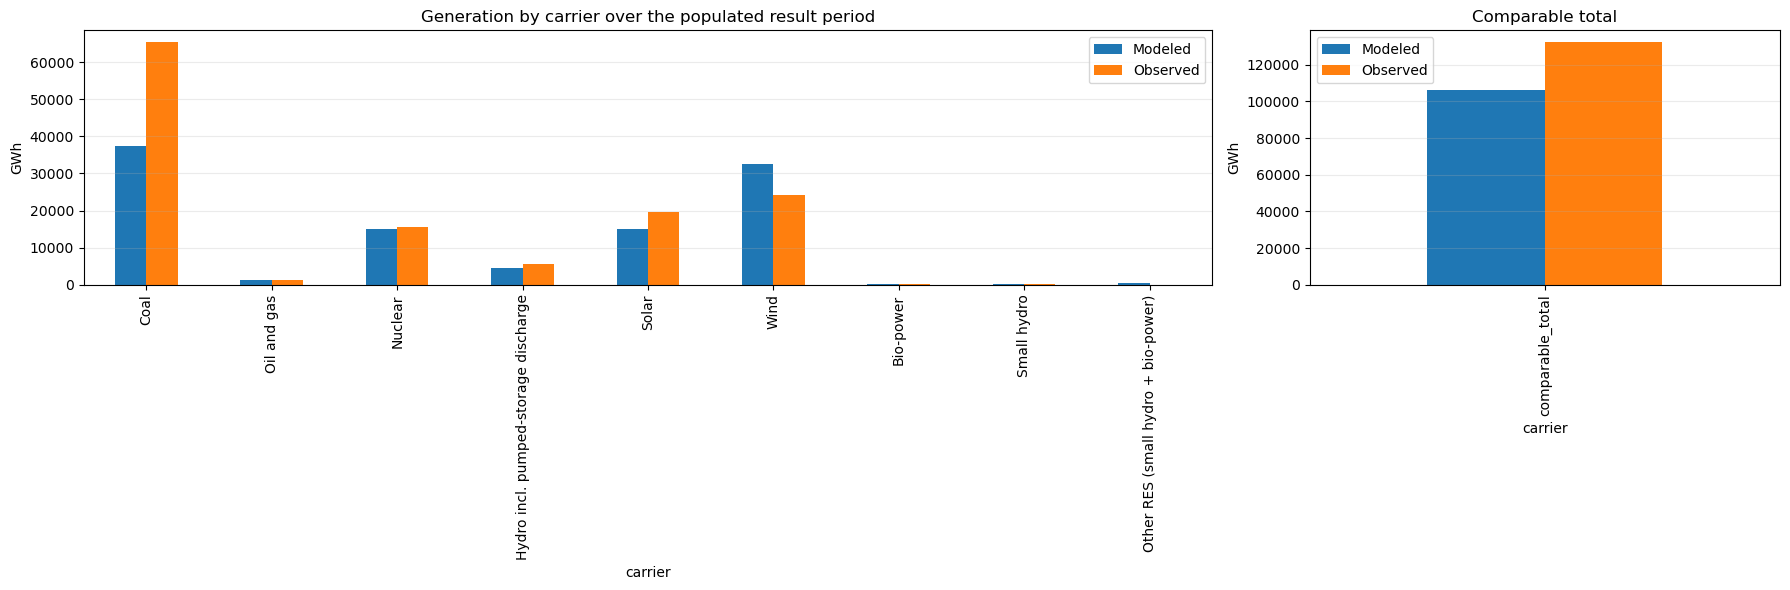

In [6]:
comparison_columns = [
    "modeled_gwh",
    "observed_gwh",
    "difference_gwh",
    "difference_pct",
]
remaining_columns = [
    column for column in analysis.period.columns if column not in comparison_columns
]
period_display = analysis.period[comparison_columns + remaining_columns].copy()
system_row = {column: float("nan") for column in period_display.columns}
system_row["modeled_gwh"] = total_generation_gwh
period_display.loc["total_generation"] = pd.Series(system_row)
demand_row = {column: float("nan") for column in period_display.columns}
demand_row["modeled_gwh"] = total_demand_gwh
period_display.loc["total_demand"] = pd.Series(demand_row)
balance_row = {column: float("nan") for column in period_display.columns}
balance_row["modeled_gwh"] = total_generation_gwh - total_demand_gwh
period_display.loc["generation_minus_demand"] = pd.Series(balance_row)
for column in period_display.select_dtypes(include="number"):
    period_display[column] = period_display[column].map(
        lambda value: f"{value:,.0f}" if pd.notna(value) else "—"
    )
display(period_display)
display(figures["period"])

## Monthly comparison

Crosses on the figure mark partial months. Months without modeled dates are omitted.

populated_days  calendar_days  coverage_pct  \
month      carrier                                                         
2025-04-01 bio_power                     30             30         100.0   
           coal                          30             30         100.0   
           comparable_total              30             30         100.0   
           hydro                         30             30         100.0   
           nuclear                       30             30         100.0   
...                                     ...            ...           ...   
2026-03-01 oil_gas                       31             31         100.0   
           other_res                     31             31         100.0   
           small_hydro                   31             31         100.0   
           solar                         31             31         100.0   
           wind                          31             31         100.0   

                             partial_month  modeled_gwh  observed_gwh  \
month      carrier                                                      
2025-04-01 bio_power                 False       18.791         17.78   
           coal                      False     4062.458       5620.93   
           comparable_total          False     8221.377       9753.50   
           hydro                     False      189.047        186.44   
           nuclear                   False     1508.460       1608.55   
...                                    ...          ...           ...   
2026-03-01 oil_gas                   False      112.300        113.03   
           other_res                 False       30.664           NaN   
           small_hydro               False       11.179         11.95   
           solar                     False     1580.979       2186.02   
           wind                      False      949.227        501.42   

                             difference_gwh  difference_pct  \
month      carrier                                            
2025-04-01 bio_power                  1.011           5.686   
           coal                   -1558.472         -27.726   
           comparable_total       -1532.123         -15.708   
           hydro                      2.607           1.398   
           nuclear                 -100.090          -6.222   
...                                     ...             ...   
2026-03-01 oil_gas                   -0.730          -0.646   
           other_res                    NaN             NaN   
           small_hydro               -0.771          -6.452   
           solar                   -605.041         -27.678   
           wind                     447.807          89.308   

                             observed_available  \
month      carrier                                
2025-04-01 bio_power                       True   
           coal                            True   
           comparable_total                True   
           hydro                           True   
           nuclear                         True   
...                                         ...   
2026-03-01 oil_gas                         True   
           other_res                      False   
           small_hydro                     True   
           solar                           True   
           wind                            True   

                                                               observed_source  
month      carrier                                                              
2025-04-01 bio_power         NITI Dashboard monthly generation + Tamil Nadu...  
           coal              NITI Dashboard monthly generation + Tamil Nadu...  
           comparable_total  NITI Dashboard monthly generation + Tamil Nadu...  
           hydro             NITI Dashboard monthly generation + Tamil Nadu...  
           nuclear           NITI Dashboard monthly generation + Tamil Nadu...  
...                                    

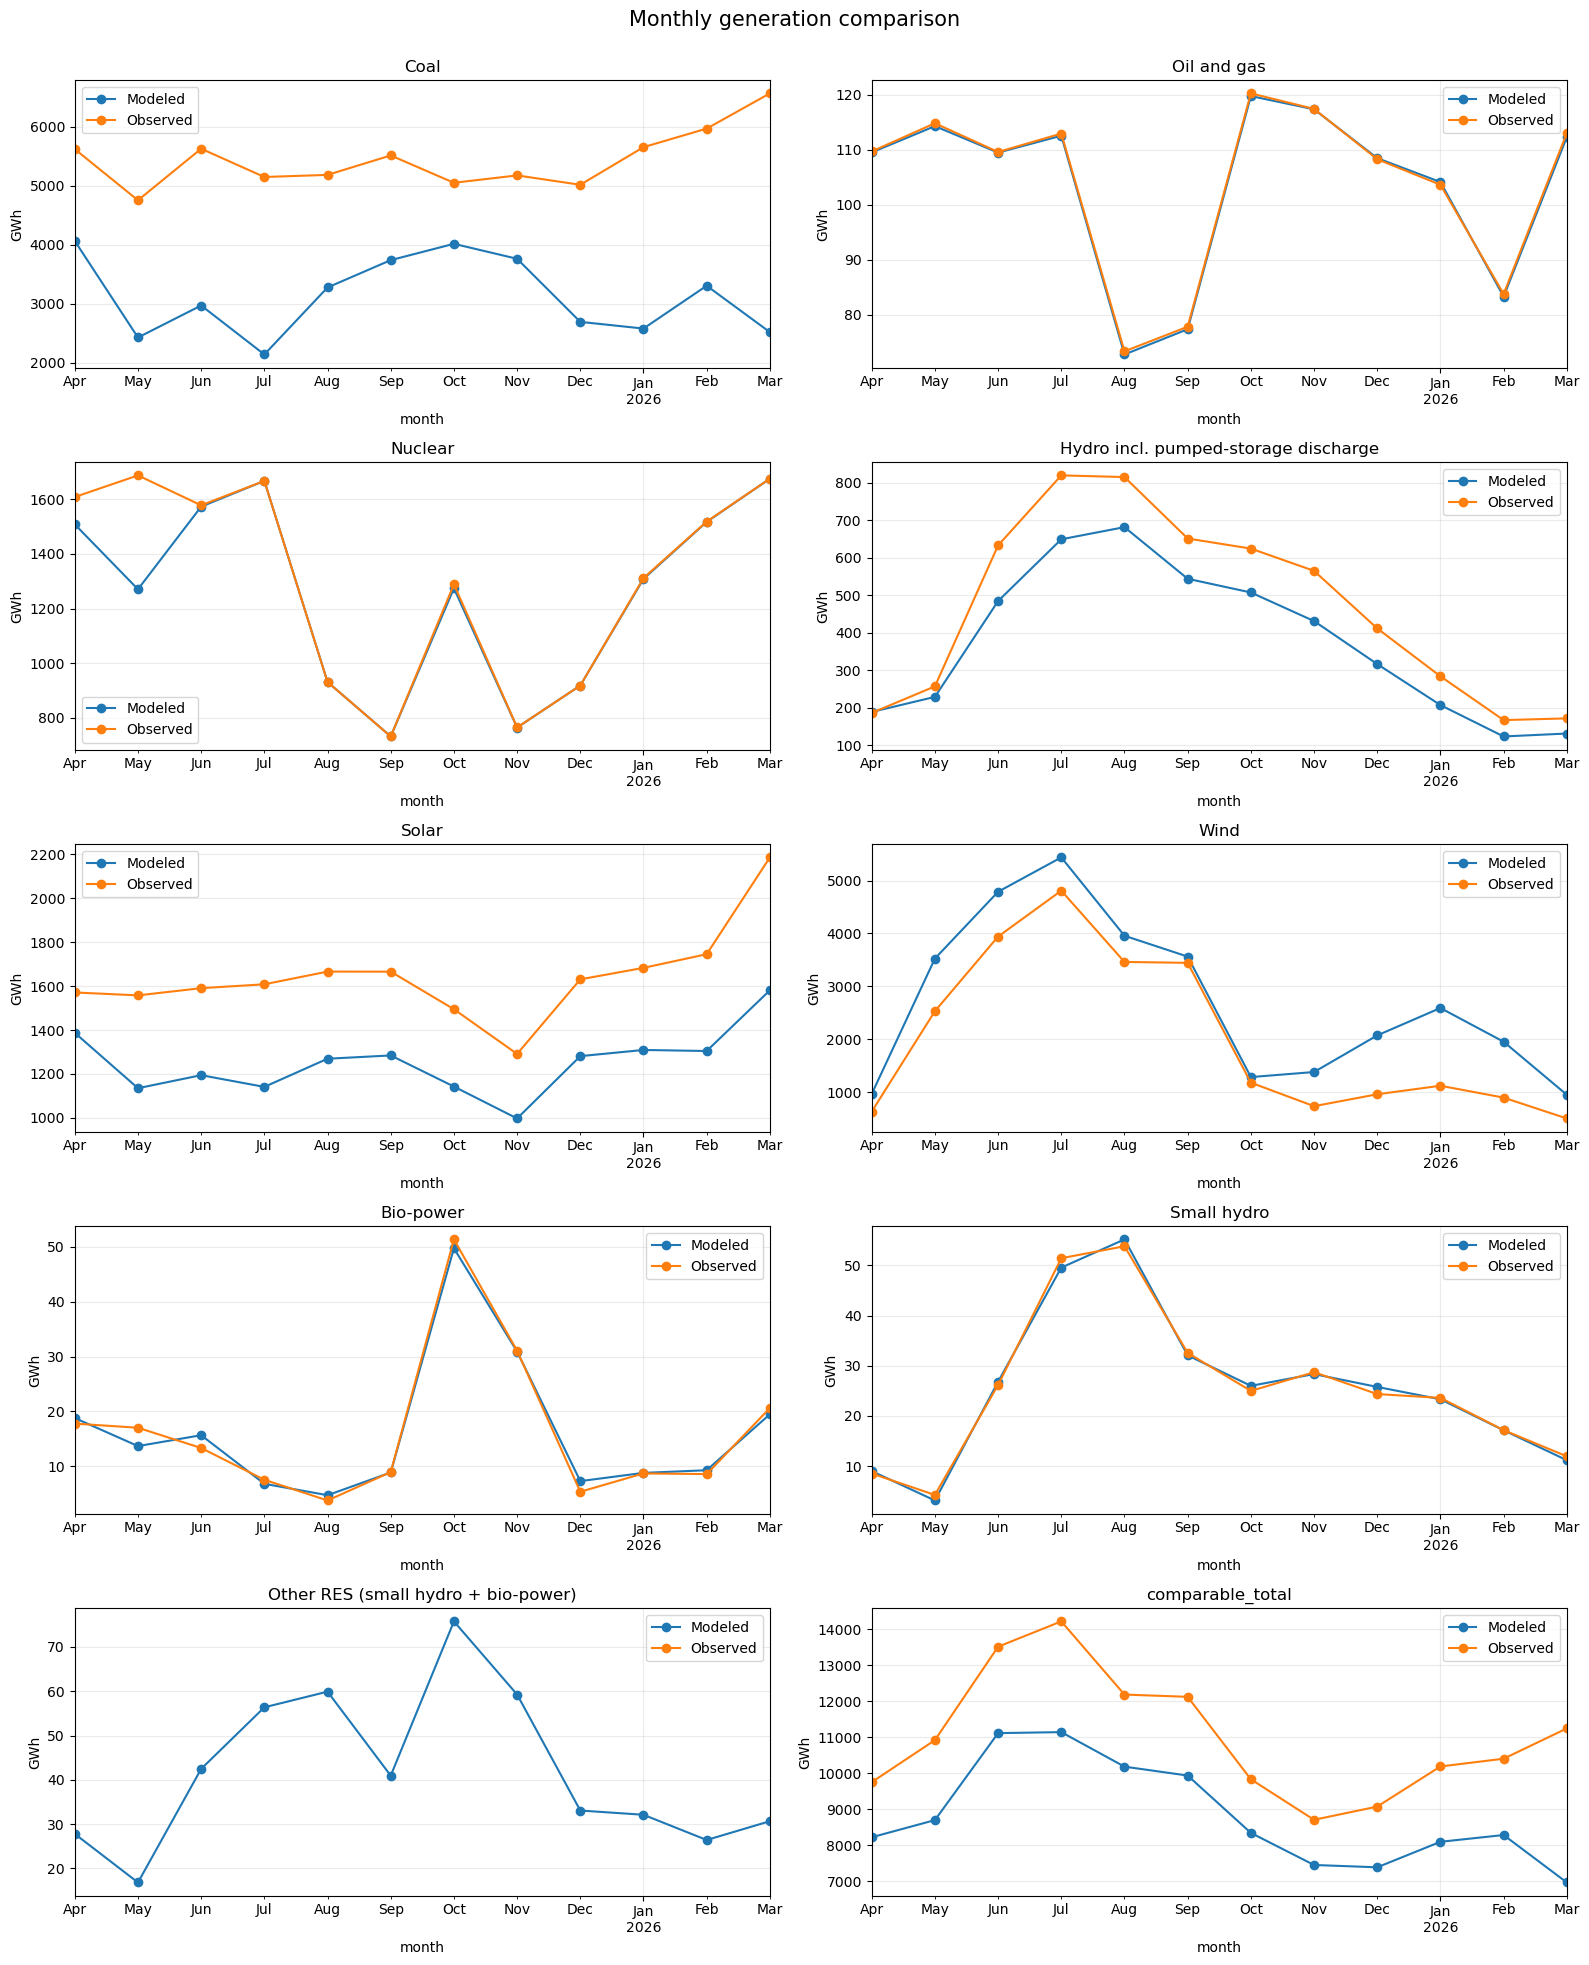

In [7]:
display(analysis.monthly.round(3))
display(figures["monthly"])

## Daily comparison

The complete daily table is exported for every carrier. Change `DAILY_DISPLAY_CARRIER` in the settings cell to inspect another carrier in the notebook.

## Demand shortfall

The demand-shortfall plots show the gross gap between modeled electricity demand and local physical generation. Imports are excluded, so this is a diagnostic of local generation adequacy rather than the model's feasibility slack. The modeled `unserved_energy` dispatch is reported separately for comparison.

In [ ]:
unserved_units = run.base.generators.index[run.base.generators.carrier.astype(str).eq("unserved_energy")]
unmet_demand_mw = (
    run.frame("generators", "p").reindex(columns=unserved_units, fill_value=0.0)
    .sum(axis=1)
    .clip(lower=0.0)
    .reindex(run.snapshots, fill_value=0.0)
)
unmet_demand_mw.name = "unmet_demand_mw"
snapshot_weights = run.weights.reindex(unmet_demand_mw.index).fillna(1.0)
unmet_demand_daily_gwh = (
    unmet_demand_mw.mul(snapshot_weights)
    .groupby(unmet_demand_mw.index.normalize())
    .sum()
    .div(1000.0)
)
unserved_energy_gwh = float(unmet_demand_daily_gwh.sum())
gross_generation_shortfall_mw = (total_demand_mw - total_generation_mw).clip(lower=0.0)
gross_generation_shortfall_daily_gwh = (
    gross_generation_shortfall_mw.mul(system_weights)
    .groupby(gross_generation_shortfall_mw.index.normalize())
    .sum()
    .div(1000.0)
)
gross_generation_shortfall_gwh = float(gross_generation_shortfall_daily_gwh.sum())
unmet_demand_summary = pd.Series({
    "unserved_energy_gwh": unserved_energy_gwh,
    "gross_generation_shortfall_gwh": gross_generation_shortfall_gwh,
    "hours_with_unmet_demand": int(unmet_demand_mw.gt(1e-6).sum()),
    "maximum_unmet_demand_mw": unmet_demand_mw.max(),
    "maximum_gross_generation_shortfall_mw": gross_generation_shortfall_mw.max(),
}, name="value")
display(unmet_demand_summary.to_frame().round(3))

demand_shortfall_figure, shortfall_axes = plt.subplots(2, 1, figsize=(14, 9), constrained_layout=True)
demand_shortfall_figure.suptitle(f"Gross demand shortfall versus local generation: {gross_generation_shortfall_gwh:,.2f} GWh")
gross_generation_shortfall_mw.plot(ax=shortfall_axes[0], color="#D62728", drawstyle="steps-post")
shortfall_axes[0].set_title("Hourly gross generation shortfall (imports excluded)")
shortfall_axes[0].set_ylabel("MW")
shortfall_axes[0].grid(alpha=0.25)
gross_generation_shortfall_daily_gwh.plot(ax=shortfall_axes[1], color="#D62728", marker="o")
shortfall_axes[1].set_title("Daily gross generation shortfall (imports excluded)")
shortfall_axes[1].set_ylabel("GWh")
shortfall_axes[1].set_xlabel("Date")
shortfall_axes[1].grid(alpha=0.25)
plt.show()

## Imports and exports

Interconnector flows are classified at the Tamil Nadu endpoint. Positive flow into a Tamil Nadu bus is an import; negative flow is an export. AC and DC interconnectors are included, and the tables retain the neighboring system and monthly direction separately. If a run has no boundary link flows, the `market_import` generator is used as the import series.

In [8]:
# Identify the modeled Tamil Nadu boundary from the actual electricity-demand buses.
electricity_demand_buses = set(
    run.base.loads.loc[run.base.loads.carrier.astype(str).eq("electricity"), "bus"]
    .dropna()
    .astype(str)
)
interconnectors = run.base.links.index[run.base.links.carrier.astype(str).isin(["AC", "DC"])]

flow_rows = []
p0 = run.frame("links", "p0").fillna(0.0)
p1 = run.frame("links", "p1").fillna(0.0)
for link in interconnectors:
    bus0 = str(run.base.links.at[link, "bus0"])
    bus1 = str(run.base.links.at[link, "bus1"])
    if bus0 in electricity_demand_buses and bus1 not in electricity_demand_buses:
        signed_import = -p0[link]
        neighbor = bus1
    elif bus1 in electricity_demand_buses and bus0 not in electricity_demand_buses:
        signed_import = -p1[link]
        neighbor = bus0
    else:
        continue
    flow_rows.append(pd.DataFrame({
        "neighbor": neighbor,
        "interconnector": link,
        "net_import_mw": signed_import,
    }))

if flow_rows:
    interconnector_flows = pd.concat(flow_rows).reset_index(names="timestamp")
else:
    # Some runs represent imports with a market_import generator instead of boundary links.
    market_import_units = run.base.generators.index[run.base.generators.carrier.astype(str).eq("market_import")]
    market_import_mw = (
        run.frame("generators", "p").reindex(columns=market_import_units, fill_value=0.0)
        .sum(axis=1)
        .clip(lower=0.0)
        .reindex(run.snapshots, fill_value=0.0)
    )
    interconnector_flows = pd.DataFrame({
        "neighbor": "market_import",
        "interconnector": "market_import",
        "net_import_mw": market_import_mw,
    }).rename_axis("timestamp").reset_index()
interconnector_flows["imports_mw"] = interconnector_flows["net_import_mw"].clip(lower=0)
interconnector_flows["exports_mw"] = (-interconnector_flows["net_import_mw"]).clip(lower=0)
interconnector_flows["weight"] = interconnector_flows["timestamp"].map(run.weights).fillna(1.0)
for column in ["imports_mw", "exports_mw", "net_import_mw"]:
    interconnector_flows[column.replace("_mw", "_mwh")] = interconnector_flows[column] * interconnector_flows["weight"]

imports_exports_by_neighbor = (
    interconnector_flows.groupby("neighbor")[["imports_mwh", "exports_mwh", "net_import_mwh"]]
    .sum()
    .div(1000)
    .rename(columns=lambda column: column.replace("mwh", "gwh"))
)
imports_exports_by_neighbor["gross_exchange_gwh"] = imports_exports_by_neighbor.imports_gwh + imports_exports_by_neighbor.exports_gwh
imports_exports_by_neighbor = imports_exports_by_neighbor.sort_values("net_import_gwh", ascending=False)

monthly_imports_exports = (
    interconnector_flows.set_index("timestamp").groupby("neighbor")[["imports_mwh", "exports_mwh"]]
    .resample("MS").sum().div(1000).rename(columns=lambda column: column.replace("mwh", "gwh"))
)
display(imports_exports_by_neighbor.round(3))
display(monthly_imports_exports.round(3))
monthly_imports_exports.unstack("neighbor").plot(kind="bar", figsize=(13, 5), width=0.85)
plt.ylabel("GWh")
plt.title("Monthly modeled imports and exports")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

ValueError: No external AC/DC interconnector flows were found

## Daily system balance

This fuel-agnostic graph compares total physical generation, total electricity demand, imports, and exports on the same daily GWh basis.

In [ ]:
daily_generation_gwh = (
    total_generation_mw.mul(system_weights)
    .groupby(total_generation_mw.index.normalize())
    .sum()
    .div(1000.0)
)
daily_demand_gwh = (
    total_demand_mw.mul(system_weights)
    .groupby(total_demand_mw.index.normalize())
    .sum()
    .div(1000.0)
)
daily_exchange_gwh = (
    interconnector_flows.assign(date=interconnector_flows["timestamp"].dt.normalize())
    .groupby("date")[["imports_mwh", "exports_mwh"]]
    .sum()
    .div(1000.0)
    .rename(columns={"imports_mwh": "imports_gwh", "exports_mwh": "exports_gwh"})
)
daily_system_balance = pd.concat([
    daily_generation_gwh.rename("generation_gwh"),
    daily_demand_gwh.rename("demand_gwh"),
    daily_exchange_gwh,
], axis=1).fillna(0.0)
display(daily_system_balance.round(3))
daily_system_balance_figure, daily_system_balance_axis = plt.subplots(figsize=(14, 5))
daily_system_balance.plot(ax=daily_system_balance_axis, linewidth=1.5)
daily_system_balance_axis.set_title("Daily generation, demand, imports, and exports")
daily_system_balance_axis.set_ylabel("GWh")
daily_system_balance_axis.set_xlabel("Date")
daily_system_balance_axis.grid(alpha=0.25)
daily_system_balance_axis.legend(title="System total")
plt.tight_layout()
plt.show()

## Sources satisfying demand

The stacked bars show daily modeled supply by generation carrier plus positive net imports. The demand line makes the source of any local-generation gap visible; storage discharge is included in its reported carrier by the generation aggregation.

In [ ]:
source_carriers = [column for column in physical_generation_mw.columns if column not in {"total"}]
daily_generation_by_source_gwh = (
    physical_generation_mw[source_carriers]
    .mul(system_weights, axis=0)
    .groupby(physical_generation_mw.index.normalize()).sum()
    .div(1000.0)
)
daily_net_imports_gwh = (daily_exchange_gwh["imports_gwh"] - daily_exchange_gwh["exports_gwh"]).clip(lower=0.0)
daily_supply_sources_gwh = daily_generation_by_source_gwh.copy()
daily_supply_sources_gwh["net_imports"] = daily_net_imports_gwh.reindex(daily_supply_sources_gwh.index, fill_value=0.0)
daily_supply_sources_gwh = daily_supply_sources_gwh.fillna(0.0)
daily_supply_sources_gwh["total_supply_gwh"] = daily_supply_sources_gwh.sum(axis=1)
daily_supply_sources_gwh["demand_gwh"] = daily_demand_gwh.reindex(daily_supply_sources_gwh.index, fill_value=0.0)
daily_supply_sources_gwh["supply_minus_demand_gwh"] = daily_supply_sources_gwh["total_supply_gwh"] - daily_supply_sources_gwh["demand_gwh"]
display(daily_supply_sources_gwh.round(3))

source_columns = [column for column in daily_supply_sources_gwh.columns if column not in {"total_supply_gwh", "demand_gwh", "supply_minus_demand_gwh"}]
source_figure, source_axis = plt.subplots(figsize=(16, 7))
daily_supply_sources_gwh[source_columns].plot(kind="bar", stacked=True, ax=source_axis, width=1.0, linewidth=0)
daily_supply_sources_gwh["demand_gwh"].plot(ax=source_axis, color="black", linewidth=1.5, label="demand")
source_axis.set_title("Daily modeled supply sources versus demand")
source_axis.set_ylabel("GWh")
source_axis.set_xlabel("Date")
source_axis.grid(axis="y", alpha=0.25)
source_axis.legend(title="Supply source", ncol=3, loc="upper left")
source_axis.set_xticks(range(0, len(daily_supply_sources_gwh), max(1, len(daily_supply_sources_gwh) // 12)))
source_axis.set_xticklabels([date.strftime("%Y-%m-%d") for date in daily_supply_sources_gwh.index[::max(1, len(daily_supply_sources_gwh) // 12)]], rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
if DAILY_DISPLAY_CARRIER not in GENERATION_CARRIERS:
    raise ValueError(f"DAILY_DISPLAY_CARRIER must be one of {GENERATION_CARRIERS}")
display(analysis.daily.xs(DAILY_DISPLAY_CARRIER, level="carrier").round(3))
display(figures["daily"])

## Aggregated renewable curtailment

Curtailment is calculated from generator availability (`p_max_pu × p_nom`) minus dispatched power, clipped at zero. The results are aggregated by renewable carrier and across wind plus solar; no unit-level series are shown. Daily values use the run's snapshot weights, so they are reported in GWh.

In [ ]:
renewable_carriers = ["wind", "solar"]
generator_meta = run.base.generators[["carrier", "p_nom"]].copy()
renewable_units = generator_meta.index[generator_meta["carrier"].astype(str).isin(renewable_carriers)]
availability_pu = run.frame("generators", "p_max_pu").reindex(columns=renewable_units).fillna(0.0)
dispatch_mw = run.frame("generators", "p").reindex(columns=renewable_units).fillna(0.0).clip(lower=0.0)
availability_mw = availability_pu.mul(generator_meta.loc[renewable_units, "p_nom"], axis=1)
curtailment_mw = availability_mw.subtract(dispatch_mw, fill_value=0.0).clip(lower=0.0)
unit_carriers = generator_meta.loc[renewable_units, "carrier"].astype(str)
aggregate_by_carrier = lambda frame: frame.T.groupby(unit_carriers).sum().T
available_by_carrier_mw = aggregate_by_carrier(availability_mw)
dispatch_by_carrier_mw = aggregate_by_carrier(dispatch_mw)
curtailment_by_carrier_mw = aggregate_by_carrier(curtailment_mw)
available_by_carrier_mw["renewables_total"] = available_by_carrier_mw.sum(axis=1)
dispatch_by_carrier_mw["renewables_total"] = dispatch_by_carrier_mw.sum(axis=1)
curtailment_by_carrier_mw["renewables_total"] = curtailment_by_carrier_mw.sum(axis=1)
weighted = run.weights.reindex(run.snapshots).fillna(1.0)
curtailment_summary = pd.DataFrame({
    "available_gwh": available_by_carrier_mw.mul(weighted, axis=0).sum() / 1000.0,
    "dispatched_gwh": dispatch_by_carrier_mw.mul(weighted, axis=0).sum() / 1000.0,
    "curtailed_gwh": curtailment_by_carrier_mw.mul(weighted, axis=0).sum() / 1000.0,
})
curtailment_summary["curtailment_pct"] = 100.0 * curtailment_summary["curtailed_gwh"] / curtailment_summary["available_gwh"].replace(0.0, pd.NA)
display(curtailment_summary.round(3))

daily_curtailment_gwh = pd.concat({
    "available_gwh": available_by_carrier_mw,
    "dispatched_gwh": dispatch_by_carrier_mw,
    "curtailed_gwh": curtailment_by_carrier_mw,
}, axis=1)
daily_curtailment_gwh = (
    daily_curtailment_gwh.mul(weighted, axis=0)
    .groupby(daily_curtailment_gwh.index.normalize()).sum()
    .div(1000.0)
)
display(daily_curtailment_gwh.round(3))

curtailment_figure, curtailment_axes = plt.subplots(2, 1, figsize=(14, 9), constrained_layout=True)
daily_total = daily_curtailment_gwh.xs("renewables_total", axis=1, level=1)
daily_total[["available_gwh", "dispatched_gwh"]].plot(ax=curtailment_axes[0], linewidth=1.5)
daily_total["curtailed_gwh"].plot(ax=curtailment_axes[1], color="#D62728", linewidth=1.5)
curtailment_axes[0].set_title("Daily aggregated renewable availability and dispatch")
curtailment_axes[0].set_ylabel("GWh")
curtailment_axes[0].grid(alpha=0.25)
curtailment_axes[1].set_title("Daily aggregated renewable curtailment")
curtailment_axes[1].set_ylabel("GWh")
curtailment_axes[1].set_xlabel("Date")
curtailment_axes[1].grid(alpha=0.25)
plt.show()

## Export

Exports the full period, monthly, daily, curtailment, and unmet-demand tables, figures, and a provenance manifest.

In [ ]:
export_path = export_generation_comparison(analysis, OUTPUT_DIR, figures)
imports_exports_by_neighbor.to_csv(export_path / "imports_exports_by_neighbor.csv")
monthly_imports_exports.to_csv(export_path / "monthly_imports_exports.csv")
system_totals.to_csv(export_path / "system_totals.csv")
daily_system_balance.to_csv(export_path / "daily_system_balance.csv")
daily_system_balance_figure.savefig(export_path / "daily_system_balance.png", dpi=160)
daily_supply_sources_gwh.to_csv(export_path / "daily_supply_sources.csv")
source_figure.savefig(export_path / "daily_supply_sources.png", dpi=160)
curtailment_summary.to_csv(export_path / "curtailment_summary.csv")
daily_curtailment_gwh.to_csv(export_path / "daily_curtailment.csv")
curtailment_figure.savefig(export_path / "curtailment.png", dpi=160)
unmet_demand_daily_gwh.rename("unmet_demand_gwh").to_csv(export_path / "unmet_demand_daily.csv")
unmet_demand_daily_gwh.rename("unserved_energy_gwh").to_csv(export_path / "unserved_energy_daily.csv")
demand_shortfall_figure.savefig(export_path / "demand_shortfall.png", dpi=160)
gross_generation_shortfall_daily_gwh.rename("gross_generation_shortfall_gwh").to_csv(export_path / "daily_demand_shortfall.csv")
print(f"Analysis written to: {export_path}")